Data loaded successfully. Shape: (395, 33)

Preprocessing completed. Columns after encoding: 43

Descriptive statistics for numeric features:
              age        Medu        Fedu  traveltime   studytime    failures  \
count  395.000000  395.000000  395.000000  395.000000  395.000000  395.000000   
mean    16.696203    2.749367    2.521519    1.448101    2.035443    0.334177   
std      1.276043    1.094735    1.088201    0.697505    0.839240    0.743651   
min     15.000000    0.000000    0.000000    1.000000    1.000000    0.000000   
25%     16.000000    2.000000    2.000000    1.000000    1.000000    0.000000   
50%     17.000000    3.000000    2.000000    1.000000    2.000000    0.000000   
75%     18.000000    4.000000    3.000000    2.000000    2.000000    0.000000   
max     22.000000    4.000000    4.000000    4.000000    4.000000    3.000000   

           famrel    freetime       goout        Dalc        Walc      health  \
count  395.000000  395.000000  395.000000  395.

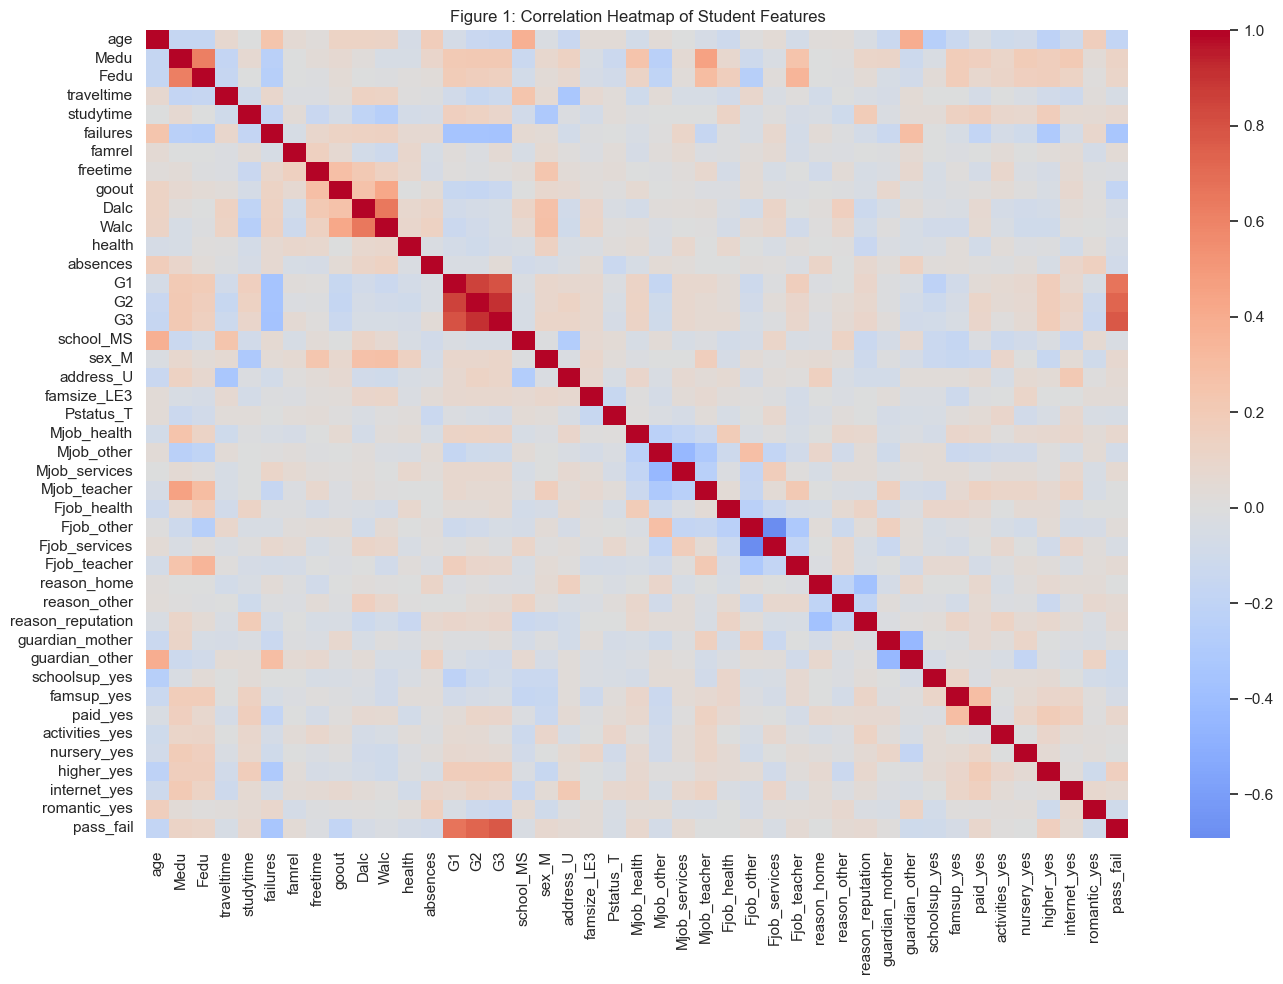

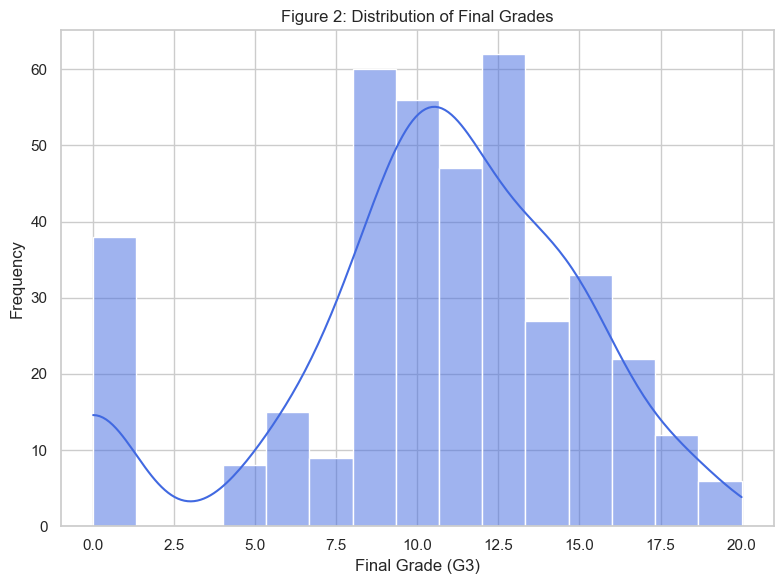

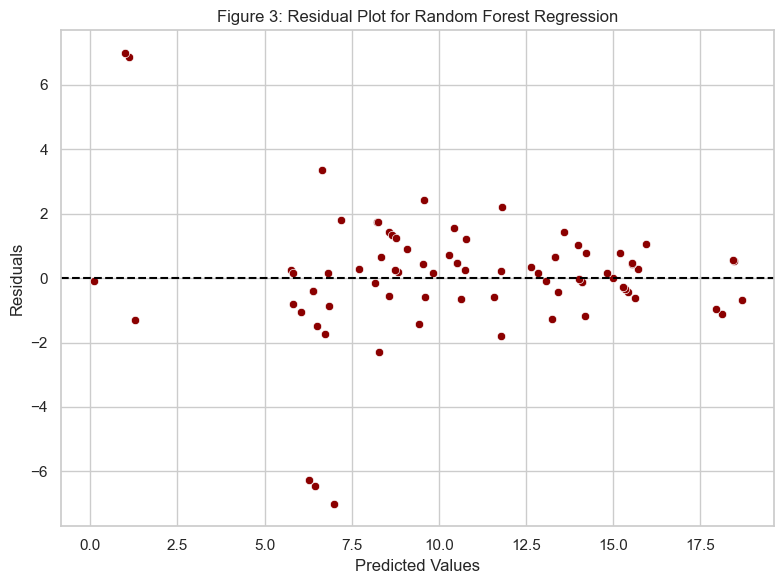

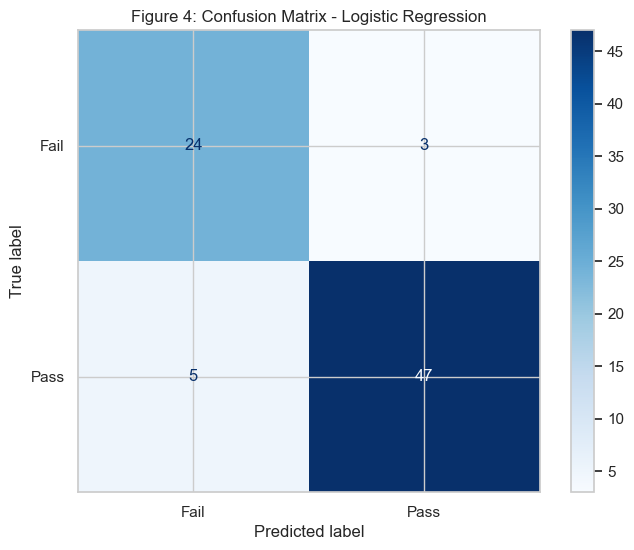

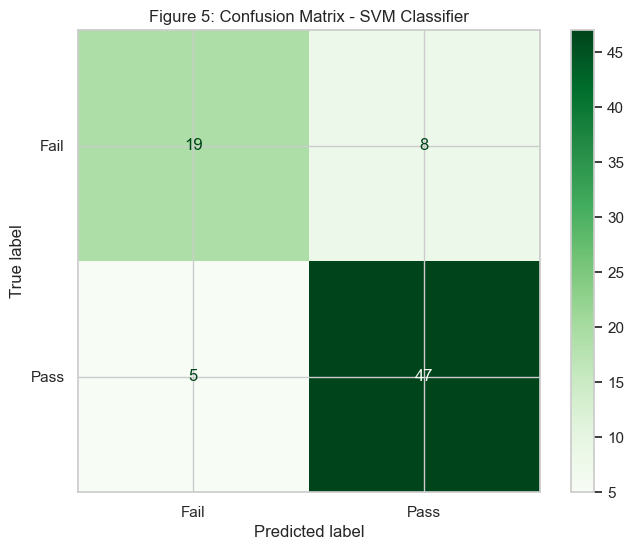

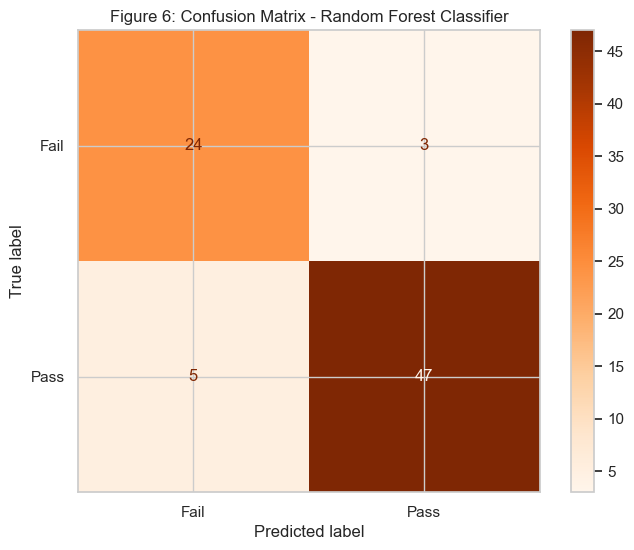


✅ Script completed successfully. All tables and figures generated.


In [1]:
# ===============================
# Import Libraries
# ===============================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    r2_score, mean_absolute_error, mean_squared_error,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay
)
import zipfile, io, requests

# Configure visuals
sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (8,6)


# ============================================================
# SECTION 1: DATA LOADING
# ============================================================
# Load datasets
mat_data = pd.read_csv('/Users/patrickpatel/Downloads/student-mat.csv', sep=';')
por_data = pd.read_csv('/Users/patrickpatel/Downloads/student-por.csv', sep=';')

# Focus on Mathematics dataset
df = mat_data.copy()
print("Data loaded successfully. Shape:", df.shape)


# ============================================================
# SECTION 2: DATA PREPROCESSING
# ============================================================

# Encode categorical variables
categorical_cols = df.select_dtypes(include=['object']).columns
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

# Create binary target column for classification
df_encoded['pass_fail'] = np.where(df_encoded['G3'] >= 10, 1, 0)

print("\nPreprocessing completed. Columns after encoding:", df_encoded.shape[1])

# Display descriptive statistics
print("\nDescriptive statistics for numeric features:")
print(df_encoded.describe())


# ============================================================
# SECTION 3: FEATURE SPLITTING AND SCALING
# ============================================================
X = df_encoded.drop(columns=['G3', 'pass_fail'])
y_reg = df_encoded['G3']
y_clf = df_encoded['pass_fail']

# Split data
X_train, X_test, y_train_reg, y_test_reg = train_test_split(X, y_reg, test_size=0.2, random_state=42)
_, _, y_train_clf, y_test_clf = train_test_split(X, y_clf, test_size=0.2, random_state=42)

# Scale numeric features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


# ============================================================
# SECTION 4: REGRESSION MODELING
# ============================================================

# --- Linear Regression ---
lin_reg = LinearRegression()
lin_reg.fit(X_train_scaled, y_train_reg)
y_pred_lin = lin_reg.predict(X_test_scaled)
r2_lin = r2_score(y_test_reg, y_pred_lin)
mae_lin = mean_absolute_error(y_test_reg, y_pred_lin)
rmse_lin = np.sqrt(mean_squared_error(y_test_reg, y_pred_lin))

# --- Ridge Regression with Hyperparameter Tuning ---
ridge = Ridge()
params = {'alpha':[0.01, 0.1, 1, 10, 100]}
ridge_grid = GridSearchCV(ridge, params, cv=5)
ridge_grid.fit(X_train_scaled, y_train_reg)
y_pred_ridge = ridge_grid.predict(X_test_scaled)
r2_ridge = r2_score(y_test_reg, y_pred_ridge)
mae_ridge = mean_absolute_error(y_test_reg, y_pred_ridge)
rmse_ridge = np.sqrt(mean_squared_error(y_test_reg, y_pred_ridge))
best_alpha_ridge = ridge_grid.best_params_['alpha']

# --- Random Forest Regression ---
rf_reg = RandomForestRegressor(n_estimators=200, random_state=42)
rf_reg.fit(X_train, y_train_reg)
y_pred_rf = rf_reg.predict(X_test)
r2_rf = r2_score(y_test_reg, y_pred_rf)
mae_rf = mean_absolute_error(y_test_reg, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test_reg, y_pred_rf))

# --- Regression Results Table ---
regression_results = pd.DataFrame({
    "Model":["Linear Regression", f"Ridge Regression (Best α={best_alpha_ridge})", "Random Forest Regression"],
    "R2":[r2_lin, r2_ridge, r2_rf],
    "MAE":[mae_lin, mae_ridge, mae_rf],
    "RMSE":[rmse_lin, rmse_ridge, rmse_rf]
})
print("\n=== Table 1: Regression Model Performance ===")
print(regression_results.to_string(index=False))


# ============================================================
# SECTION 5: CLASSIFICATION MODELING
# ============================================================

# --- Logistic Regression ---
log_clf = LogisticRegression(max_iter=1000)
log_clf.fit(X_train_scaled, y_train_clf)
y_pred_log = log_clf.predict(X_test_scaled)

# --- SVM Classifier ---
svm_clf = SVC(C=1.0, kernel='rbf')
svm_clf.fit(X_train_scaled, y_train_clf)
y_pred_svm = svm_clf.predict(X_test_scaled)

# --- Random Forest Classifier ---
rf_clf = RandomForestClassifier(n_estimators=200, random_state=42)
rf_clf.fit(X_train, y_train_clf)
y_pred_rf_clf = rf_clf.predict(X_test)

# --- Classification Metrics Table ---
classification_results = pd.DataFrame({
    "Model":["Logistic Regression", "SVM Classifier", "Random Forest Classifier"],
    "Accuracy":[accuracy_score(y_test_clf, y_pred_log),
                accuracy_score(y_test_clf, y_pred_svm),
                accuracy_score(y_test_clf, y_pred_rf_clf)],
    "Precision":[precision_score(y_test_clf, y_pred_log),
                 precision_score(y_test_clf, y_pred_svm),
                 precision_score(y_test_clf, y_pred_rf_clf)],
    "Recall":[recall_score(y_test_clf, y_pred_log),
              recall_score(y_test_clf, y_pred_svm),
              recall_score(y_test_clf, y_pred_rf_clf)],
    "F1 Score":[f1_score(y_test_clf, y_pred_log),
                f1_score(y_test_clf, y_pred_svm),
                f1_score(y_test_clf, y_pred_rf_clf)]
})
print("\n=== Table 2: Classification Model Performance ===")
print(classification_results.to_string(index=False))


# ============================================================
# SECTION 6: VISUALIZATIONS (FIGURES)
# ============================================================

# --- Figure 1: Correlation Heatmap ---
plt.figure(figsize=(14,10))
sns.heatmap(df_encoded.corr(), cmap="coolwarm", center=0)
plt.title("Figure 1: Correlation Heatmap of Student Features")
plt.tight_layout()
plt.show()

# --- Figure 2: Distribution of Final Grades ---
plt.figure(figsize=(8,6))
sns.histplot(df_encoded['G3'], bins=15, kde=True, color='royalblue')
plt.title("Figure 2: Distribution of Final Grades")
plt.xlabel("Final Grade (G3)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

# --- Figure 3: Residual Plot for Random Forest Regression ---
residuals_rf = y_test_reg - y_pred_rf
plt.figure(figsize=(8,6))
sns.scatterplot(x=y_pred_rf, y=residuals_rf, color='darkred')
plt.axhline(0, linestyle='--', color='black')
plt.title("Figure 3: Residual Plot for Random Forest Regression")
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.tight_layout()
plt.show()

# --- Figure 4–6: Confusion Matrices ---
models = {
    "Logistic Regression": (y_test_clf, y_pred_log, "Blues"),
    "SVM Classifier": (y_test_clf, y_pred_svm, "Greens"),
    "Random Forest Classifier": (y_test_clf, y_pred_rf_clf, "Oranges")
}

for i, (name, (y_true, y_pred, color)) in enumerate(models.items(), start=4):
    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=["Fail","Pass"])
    disp.plot(cmap=color)
    plt.title(f"Figure {i}: Confusion Matrix - {name}")
    plt.show()

print("\n✅ Script completed successfully. All tables and figures generated.")
